# Clustering Track
**Dataset:** UCI *Multiple Features* (mfeat): 2,000 handwritten digits (0-9, 200 each) from Dutch utility maps, described by six feature sets, 649 features in total.

**Algorithms:** K-Means (elbow curve to choose k) and Agglomerative Hierarchical clustering (dendrogram, comparison of linkage strategies).

**Metrics:** Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index for every algorithm; PCA (2 components) plots for every algorithm; t-SNE plot.

**Rule:** the digit labels (implied by row order) are **never** passed to a fit. They are used only after clustering, to validate the result (ARI, NMI, contingency tables).

In [1]:
# Make the project's src/ package importable from notebooks/
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 80)

## 1. Load and combine the six feature sets

In [2]:
from src import config as C, data_loader as dl, clustering as clu, visualize as viz

X_raw, y_true, feat_names = dl.load_mfeat()   # y_true kept aside for post-hoc checks only
print('Shape:', X_raw.shape, ' Missing values:', int(np.isnan(X_raw).sum()))
pd.DataFrame({'File': [f'mfeat-{s}' for s in C.MFEAT_SETS],
              'Description': [C.MFEAT_DESC[s] for s in C.MFEAT_SETS]})

Shape: (2000, 649)  Missing values: 0


,File,Description
0,mfeat-fou,Fourier coefficients (76)
1,mfeat-fac,Profile correlations (216)
2,mfeat-kar,Karhunen-Loeve coefficients (64)
3,mfeat-pix,Pixel averages 2x3 windows (240)
4,mfeat-zer,Zernike moments (47)
5,mfeat-mor,Morphological features (6)


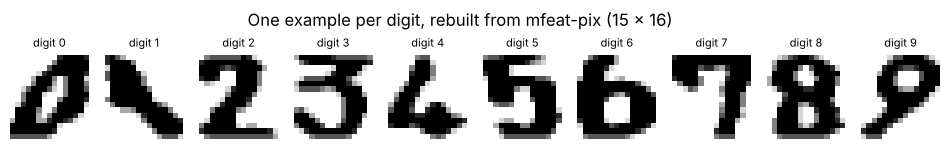

In [3]:
fig, axes = plt.subplots(1, 10, figsize=(12, 1.8))
for d, ax in enumerate(axes):
    ax.imshow(dl.pixel_image(d * 200 + 5), cmap='gray_r'); ax.set_title(f'digit {d}', fontsize=8); ax.axis('off')
fig.suptitle('One example per digit, rebuilt from mfeat-pix (15 x 16)');

## 2. Preprocessing
The six feature blocks are standardised (zero mean, unit variance), because both algorithms use Euclidean distances and the blocks are on very different scales.

In [4]:
print('Value range per block before scaling:')
start = 0
for s in C.MFEAT_SETS:
    w = int(C.MFEAT_DESC[s].split('(')[1].rstrip(')'))
    print(f'  {s}: {X_raw[:, start:start+w].min():9.2f} to {X_raw[:, start:start+w].max():9.2f}')
    start += w
X, scaler = clu.scale(X_raw)
print('After scaling: mean', X.mean().round(6), ' std', X.std().round(3))

Value range per block before scaling:
  fou:      0.00 to      0.80
  fac:      0.00 to   1353.00
  kar:    -16.46 to     17.05
  pix:      0.00 to      6.00
  zer:      0.00 to    777.86
  mor:      0.00 to  17572.20
After scaling: mean -0.0  std 1.0


## 3. K-Means: elbow curve (inertia vs. k)
K-Means is fitted for k = 2 to 15. The table also shows silhouette per k, the percentage drop in inertia from the previous k, and an automatic knee estimate (point farthest from the line joining the curve's endpoints). The value of k used below is set in `src/config.py` (`K_FINAL`).

In [5]:
elbow = clu.elbow_analysis(X)
elbow['inertia drop %'] = (-elbow['inertia'].pct_change() * 100).round(2)
k_auto = clu.find_elbow(elbow['k'], elbow['inertia'])
k_sil = int(elbow.loc[elbow['silhouette'].idxmax(), 'k'])
K = C.K_FINAL
print(f'automatic knee = {k_auto}, best silhouette = {k_sil}, k used = {K}')
elbow

automatic knee = 6, best silhouette = 9, k used = 10


,k,inertia,silhouette,inertia drop %
0,2,1.1533e+06,0.1092,NaN
1,3,1.0619e+06,0.1094,7.93
2,4,9.8315e+05,0.1189,7.41
3,5,9.3489e+05,0.1287,4.91
4,6,8.9377e+05,0.1357,4.40
5,7,8.6037e+05,0.1406,3.74
6,8,8.3103e+05,0.1465,3.41
7,9,8.0413e+05,0.1470,3.24
8,10,7.8330e+05,0.1325,2.59
9,11,7.6218e+05,0.1375,2.70


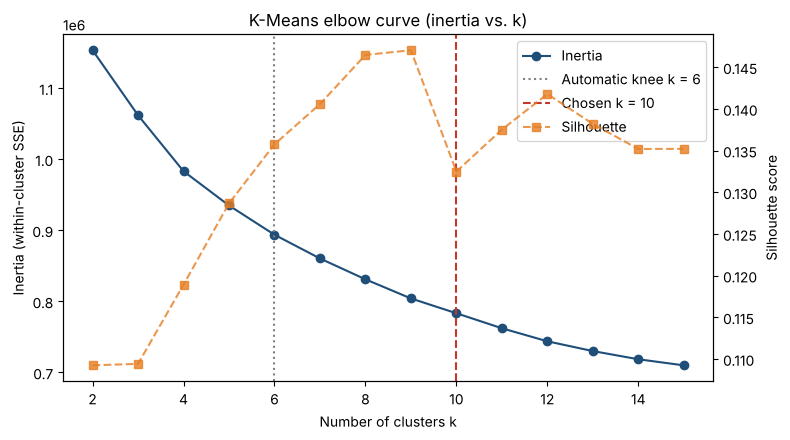

In [6]:
viz.elbow_plot(elbow, K, k_auto=k_auto);

Sensitivity check: both algorithms at each candidate k (ARI/NMI are post-hoc only).

In [7]:
sens = []
for kk in sorted({k_auto, k_sil, K}):
    for algo, lab in (('K-Means', clu.fit_kmeans(X, kk).labels_),
                      ('Agglomerative (ward)', clu.fit_agglomerative(X, kk).labels_)):
        sens.append({'k': kk, 'Algorithm': algo, **clu.internal_metrics(X, lab),
                     **clu.external_validation(y_true, lab)})
pd.DataFrame(sens)

,k,Algorithm,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI,NMI
0,6,K-Means,0.1358,2.2272,180.3663,0.5330,0.6846
1,6,Agglomerative (ward),0.1266,2.2364,170.5096,0.6121,0.7887
2,9,K-Means,0.1483,2.2015,152.8930,0.7220,0.8000
3,9,Agglomerative (ward),0.1423,2.2578,146.3052,0.8136,0.8817
4,10,K-Means,0.1325,2.2376,145.2921,0.8376,0.8569
5,10,Agglomerative (ward),0.1286,2.2943,139.3618,0.9026,0.9116


> **✍️ Team observation — write this in your own words before submission.**
>
> Questions to answer:
> - Where is the elbow in the curve? Is it sharp or gradual?
> - Justify the value of k you use. What evidence supports it (elbow, silhouette, domain knowledge)?
> - How do the metrics in the sensitivity table change with k?
>
> _Your answer here._

In [8]:
km = clu.fit_kmeans(X, K)
pd.Series(clu.internal_metrics(X, km.labels_))

Silhouette             0.1325
Davies-Bouldin         2.2376
Calinski-Harabasz    145.2921
dtype: float64

## 4. Agglomerative hierarchical clustering: comparing linkage strategies
Four linkages at the same k: **ward** (minimises the increase in within-cluster variance), **complete** (maximum pairwise distance), **average** (mean pairwise distance) and **single** (minimum pairwise distance). Cluster sizes are shown alongside the metrics.

In [9]:
link_table, agg_models = clu.compare_linkages(X, K)
link_table

,Linkage,Silhouette,Davies-Bouldin,Calinski-Harabasz,Largest cluster,Smallest cluster
0,ward,0.1286,2.2943,139.3618,234,174
1,complete,0.0660,2.5599,86.9448,483,29
2,average,0.0888,1.5535,61.0417,968,1
3,single,-0.0160,0.8118,1.5586,1991,1


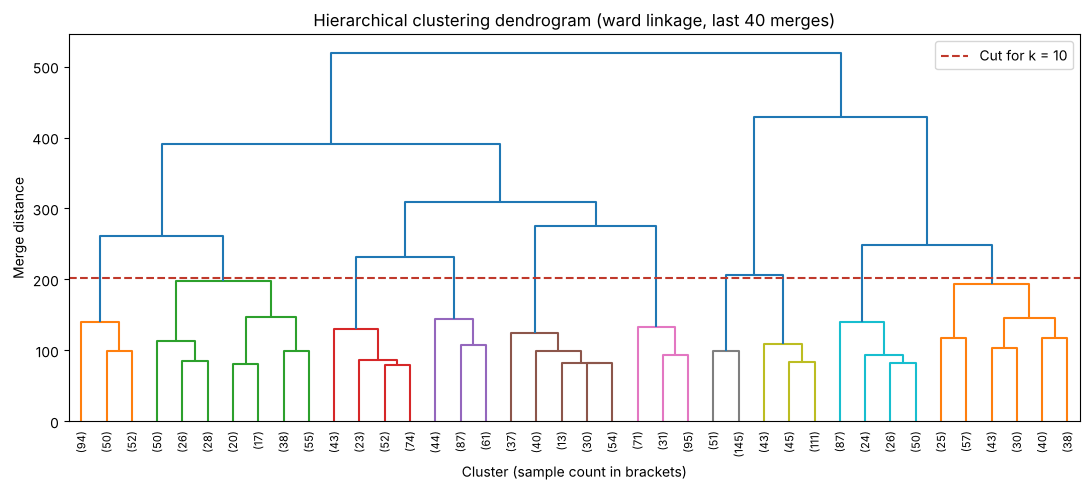

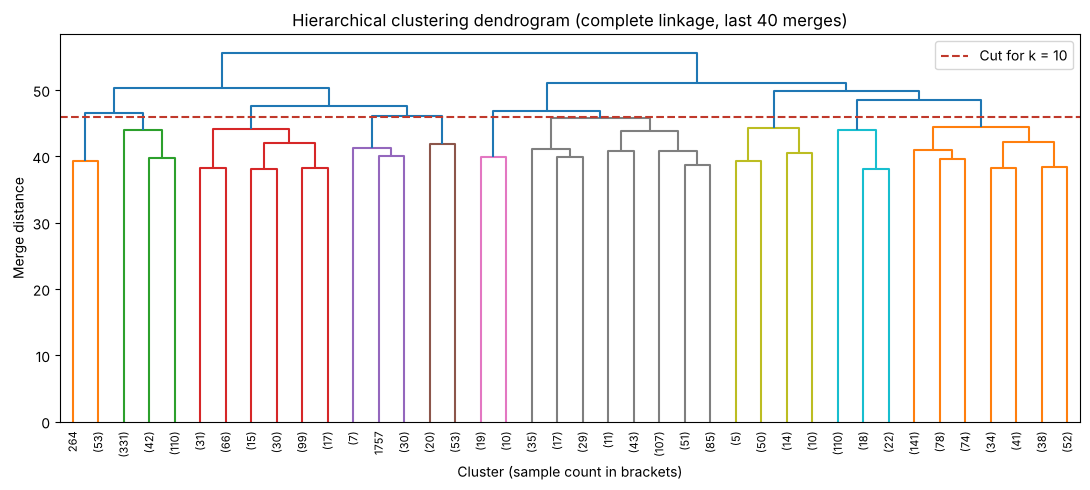

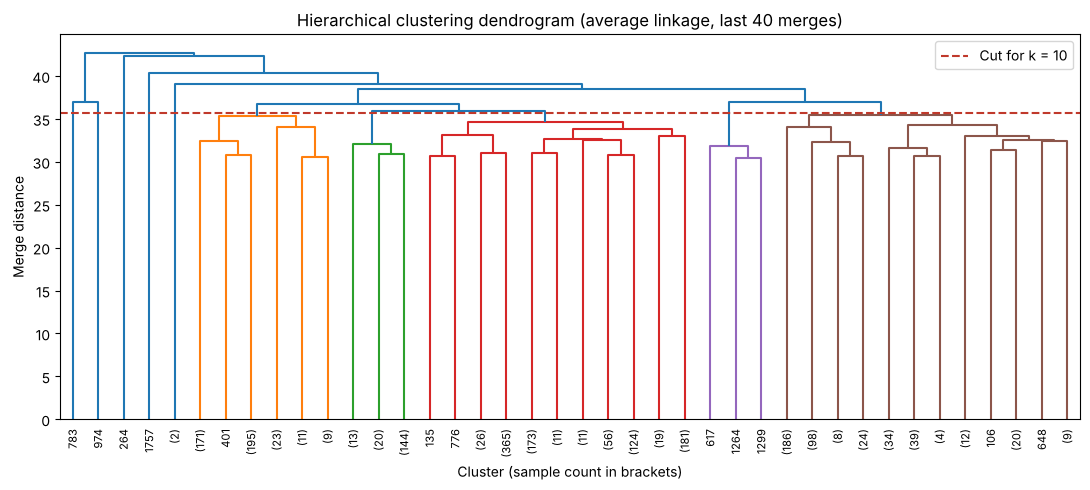

In [10]:
for method in ['ward', 'complete', 'average']:
    viz.dendrogram_plot(clu.linkage_matrix(X, method), K, method)

> **✍️ Team observation — write this in your own words before submission.**
>
> Questions to answer:
> - Compare the four linkages: metrics and cluster sizes. Which would you choose and why?
> - Does any metric look good for a linkage whose clusters are clearly poor? What does that tell you?
> - What does the dendrogram show around the cut for your chosen k?
>
> _Your answer here._

## 5. Evaluation: all three metrics for every algorithm

In [11]:
all_labels = {'K-Means': km.labels_, **{f'Agglomerative ({lk})': m.labels_ for lk, m in agg_models.items()}}
metrics = pd.DataFrame([{'Algorithm': n, **clu.internal_metrics(X, l)} for n, l in all_labels.items()])
metrics

,Algorithm,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,K-Means,0.1325,2.2376,145.2921
1,Agglomerative (ward),0.1286,2.2943,139.3618
2,Agglomerative (complete),0.0660,2.5599,86.9448
3,Agglomerative (average),0.0888,1.5535,61.0417
4,Agglomerative (single),-0.0160,0.8118,1.5586


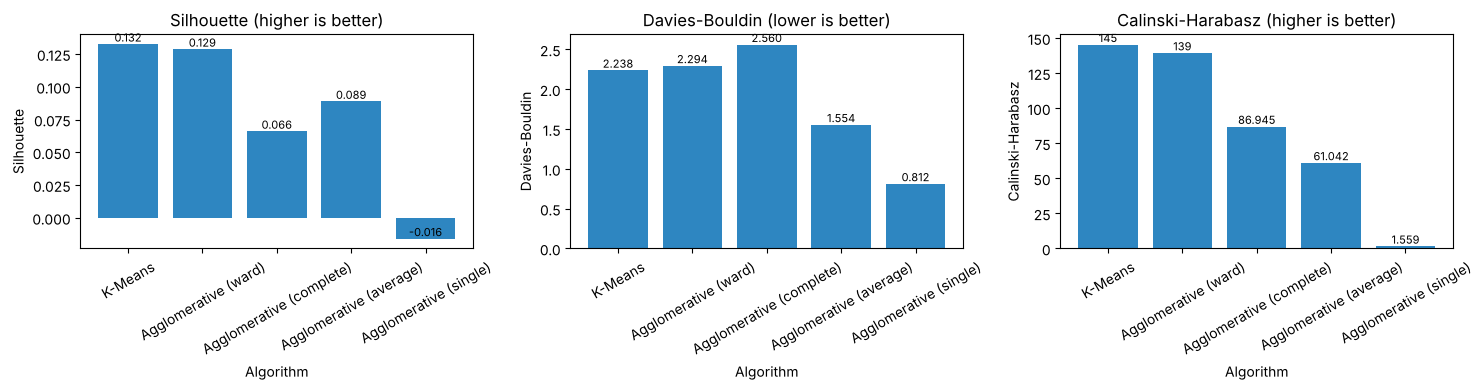

In [12]:
viz.metric_bars(metrics, 'Algorithm');

| Metric | Meaning | Better |
|---|---|---|
| Silhouette | How much closer a point is to its own cluster than to the nearest other cluster (−1 to 1) | higher |
| Davies-Bouldin | Average ratio of within-cluster spread to between-cluster separation | lower |
| Calinski-Harabasz | Between-cluster dispersion ÷ within-cluster dispersion | higher |

> **✍️ Team observation — write this in your own words before submission.**
>
> Questions to answer:
> - How do K-Means and the chosen Agglomerative model compare on the three metrics?
> - Are the absolute silhouette values high or low? What could explain that for this data?
>
> _Your answer here._

## 6. Visualisation: PCA (2 components) for every algorithm

Variance explained by PC1 + PC2: 0.248


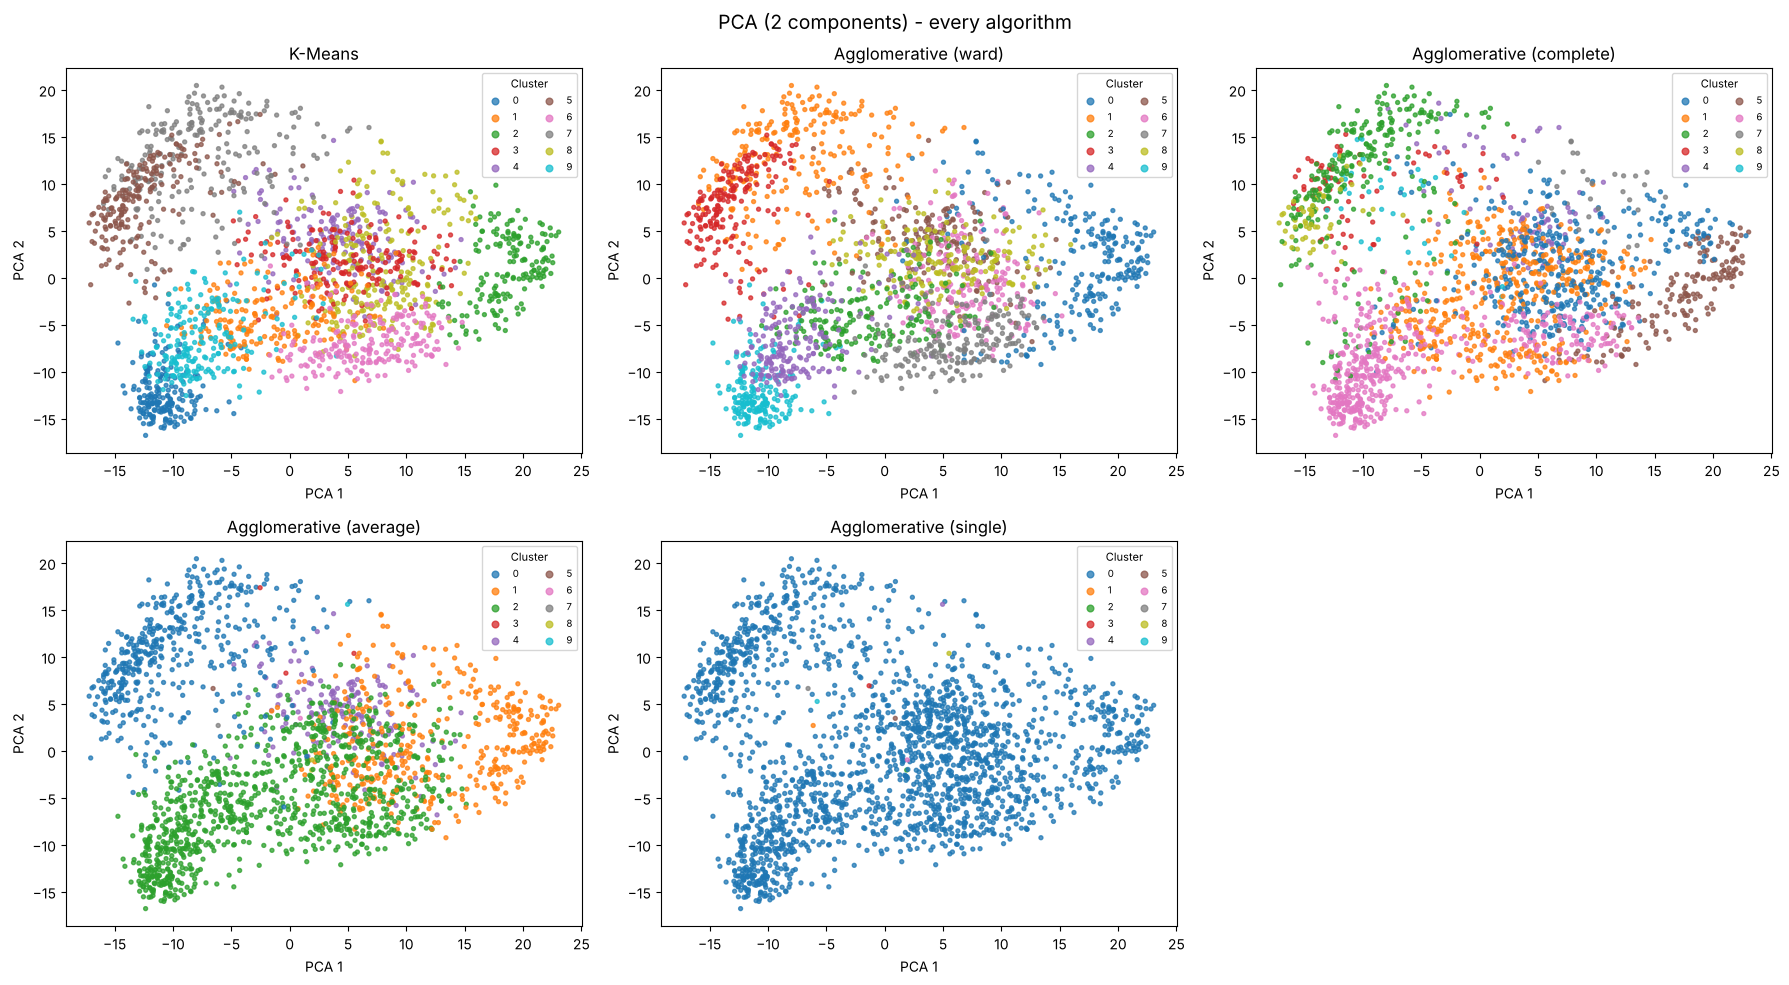

In [13]:
pca_xy, pca = clu.pca_2d(X)
print('Variance explained by PC1 + PC2:', pca.explained_variance_ratio_.sum().round(3))
viz.scatter_grid(pca_xy, all_labels, 'PCA', 'PCA (2 components) - every algorithm');

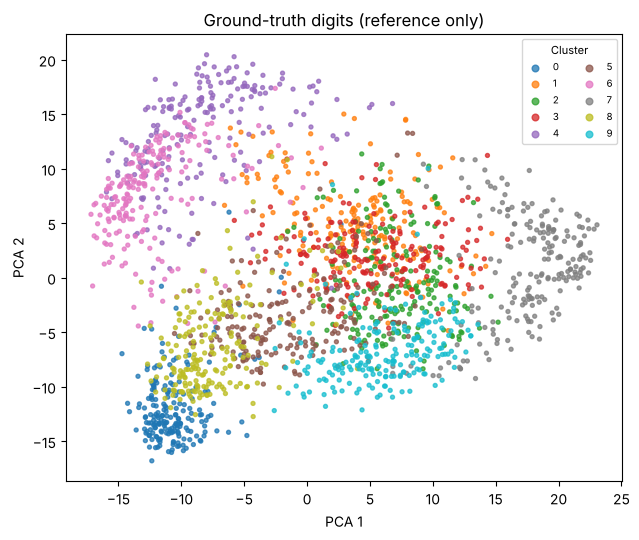

In [14]:
viz.scatter_clusters(pca_xy, y_true, 'Ground-truth digits (reference only)');

## 7. Visualisation: t-SNE
Data is reduced to 50 PCA components first, then embedded with t-SNE (perplexity 30).

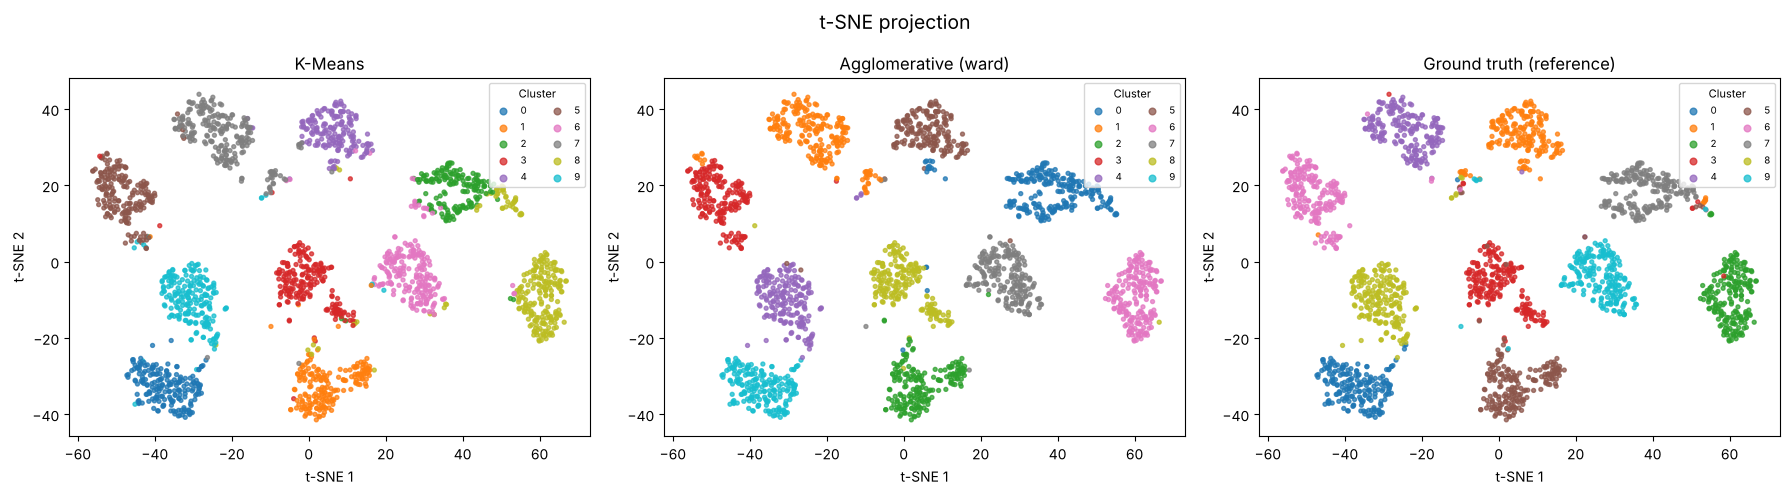

In [15]:
tsne_xy = clu.tsne_2d(X)
viz.scatter_grid(tsne_xy, {'K-Means': km.labels_, 'Agglomerative (ward)': agg_models['ward'].labels_,
                           'Ground truth (reference)': y_true}, 't-SNE', 't-SNE projection');

> **✍️ Team observation — write this in your own words before submission.**
>
> Questions to answer:
> - How do the PCA and t-SNE views differ, and why? (Consider how much variance 2 PCA components keep.)
> - Which clusters are well separated and which overlap?
>
> _Your answer here._

## 8. Post-hoc validation against the true digits
Only now are the labels used: **ARI** (Adjusted Rand Index; 0 = random, 1 = perfect) and **NMI** (Normalized Mutual Information), plus a cluster × digit contingency table.

In [16]:
ext = pd.DataFrame([{'Algorithm': n, **clu.external_validation(y_true, l)} for n, l in all_labels.items()])
metrics.merge(ext, on='Algorithm')

,Algorithm,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI,NMI
0,K-Means,0.1325,2.2376,145.2921,8.3764e-01,0.8569
1,Agglomerative (ward),0.1286,2.2943,139.3618,9.0256e-01,0.9116
2,Agglomerative (complete),0.0660,2.5599,86.9448,2.9624e-01,0.4914
3,Agglomerative (average),0.0888,1.5535,61.0417,3.0946e-01,0.5774
4,Agglomerative (single),-0.0160,0.8118,1.5586,4.6618e-07,0.0089


Cluster,0,1,2,3,4,5,6,7,8,9
Majority digit,0.00,5.000,7.000,3.000,1.000,6.000,9.000,4.000,2.000,8.000
Purity,0.99,0.973,0.976,0.959,0.988,0.974,0.873,0.854,0.789,0.933
Size,195.00,188.000,164.000,193.000,173.000,193.000,213.000,226.000,247.000,208.000


Cluster,0,1,2,3,4,5,6,7,8,9
Majority digit,7.000,4.00,5.000,6.000,8.000,1.000,2.000,9.000,3.000,0.0
Purity,0.855,0.85,0.979,0.995,0.985,0.983,0.995,0.985,0.974,1.0
Size,234.000,233.00,192.000,187.000,199.000,174.000,196.000,197.000,192.000,196.0


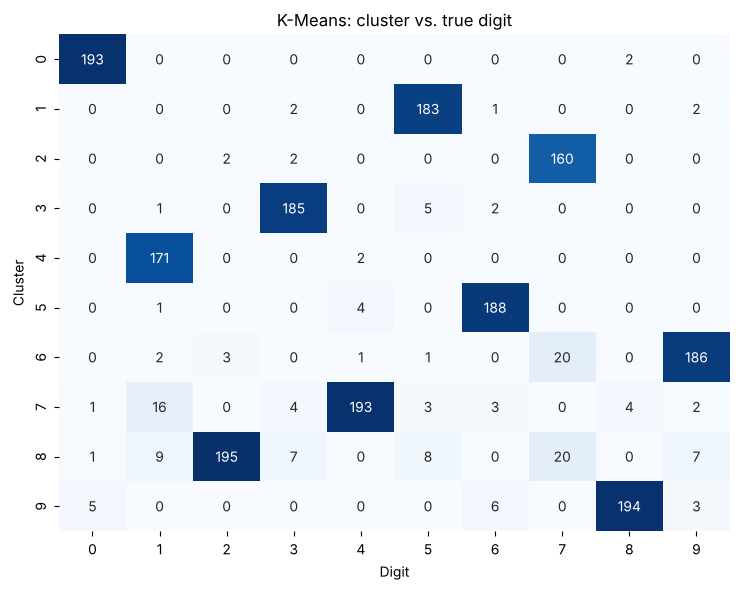

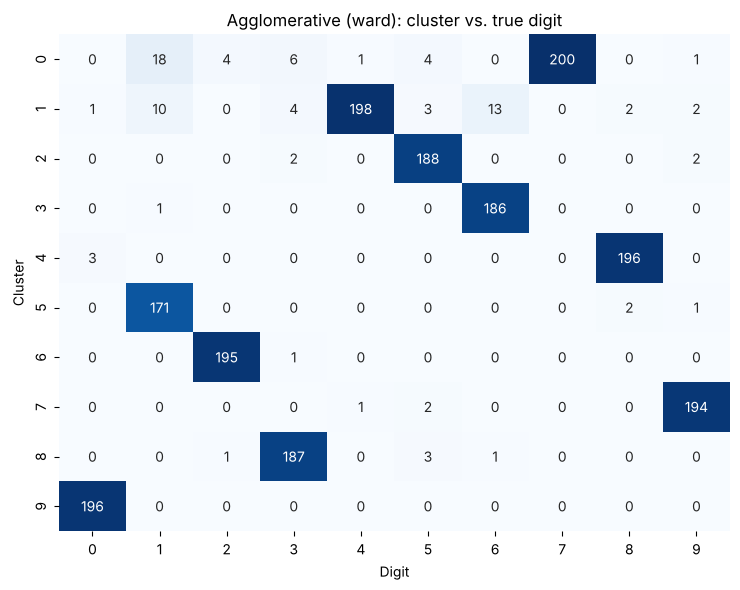

In [17]:
for name, lab in [('K-Means', km.labels_), ('Agglomerative (ward)', agg_models['ward'].labels_)]:
    mapping, ct = clu.map_clusters_to_digits(y_true, lab)
    viz.contingency_heatmap(ct, f'{name}: cluster vs. true digit')
    display(mapping.T)

> **✍️ Team observation — write this in your own words before submission.**
>
> Questions to answer:
> - Which algorithm agrees best with the true digits? Does that match the internal metrics?
> - Which digits get mixed up, and why might they look similar in feature space?
>
> _Your answer here._

## 9. Conclusion

> **✍️ Team observation — write this in your own words before submission.**
>
> Questions to answer:
> - Summarise the clustering results: which algorithm and linkage you recommend and why.
> - Trade-offs between K-Means and Agglomerative clustering (scalability, predicting new points, determinism, interpretability of the hierarchy).
>
> _Your answer here._